# Joint vs R2D2M2 vs stated scales on real designs, refitted by lme4

## 1. Motivation

The [simulated datasets](simulated.ipynb) compared three ways to set the prior scales of a Bayesian generalized linear mixed model (GLMM).<br>
Only the joint prior kept the marginal R² and the links' saturation flat as the design grew.<br>
But that comparison read every measure off the ground truth, on simulated covariates.<br>
So it could not say whether a prior's levels match those of real grouped tables.

This experiment draws y on the designs of real tables instead.<br>
lme4 refits each drawn y, as it fitted the real one.<br>
If a prior could have produced the real tables, each real fit falls at a random rank among its refits.

**Contents**
1. Motivation
2. Design
3. Measures
4. Reading
5. Records
6. Ranks
7. Outside, containment and distance
8. Singular fits and the slope over d
9. Saturation
10. The joint prior split by its draws
11. Candidate defaults by reweighting
12. φ ~ Beta(2, 3) as its own prior
13. Finding

References

## 2. Design

Each real table lends its design to every prior, and lme4 (Bates et al., 2015) fits both sides alike.
- **Registry:** real grouped tables from public sources, each with the mixed model its documentation fits, collected and fitted by lme4 in MixedBench 1.0.12.
- **Fits:** each documented model with estimates and an intercept, on the rows it was fitted on (section 5 counts the rest).
- **Design:** the design matrix X and each grouping factor's random-effect columns Z_k, as lme4 builds them from the documented formula, with its offset.
- **Columns:** X's columns other than 0/1 z-scored, which the refit's intercept and slopes absorb.
- **Draws:** each a prior, its parameters and a y in the family the registry fitted (Gaussian, Bernoulli or Poisson).
- **Refits:** per fit and prior, draws until 39 refits have estimates, at most 78, since the registry holds only fits with estimates.
- **Random effects:** correlated as the formula fits them, under a Lewandowski-Kurowicka-Joe (LKJ) prior for `(x | g)` and independent for `(x || g)`.
- **Refit:** the documented formula with the drawn y as its response, so each refit is the registry's fit with y swapped.
- **Priors:** the five of [simulated.ipynb's section 4](simulated.ipynb), `joint`, `r2d2m2-0.5`, `r2d2m2-1`, `survey` and `unit`.
- **`joint-phi`:** the joint prior with φ ~ Beta(2, 3), on the 510 fits whose joint refits took a median of at most 120 s (section 12).
- **Random streams:** shared by every prior, so that the five differ only in their scales, and `joint-phi` from the joint prior only in φ and the draws after it.
- **Recorded draws:** what the prior drew, beside each refit and its ground truth.
- **Real refit:** each real y refitted once, on the same machine as the drawn ones, for the max |η̂| the registry lacks.

`registry.py` builds the designs and draws and refits y, one cluster task per fit, and writes `registry.csv.gz` and `registry-real.csv`, which this notebook reads.

## 3. Measures

Each measure is read off a fit's estimates, the refit's or the registry's, by the variance partition of [simulated.ipynb's section 3](simulated.ipynb) (Nakagawa et al., 2017).
- **$R^2_m$, $R^2_c$ and the fixed share $R^2_m / R^2_c$:** one per fit.
- **Intraclass correlation (ICC):** one per grouping factor, every factor in one distribution, each paired with the same factor of the registry's fit.
- **sd(η):** the standard deviation of the fitted linear predictor over the rows, on the logit and log links only, since a Gaussian η is on y's raw scale.
- **Singular share:** the share of fits that lme4 flags as singular, with some variance estimated at 0 or some correlation at ±1.
- **Saturated share:** the share of fits with some |η̂| above 10, on the logit and log links only.
- **y's mean:** over the fit's rows, the real y's and each drawn y's, on the logit and log links only, read off the data rather than a fit.

A fit without slopes (d = 1) has $R^2_m$ = 0 and a fixed share of 0 on both sides.<br>
So it leaves those two measures, whose ties would otherwise pull its ranks toward uniform.

## 4. Reading

### Ranks

A registry fit's rank among the m refits under one prior runs from 0, below every refit, to m, above every refit.<br>
If real tables were draws from the prior, the rank would be uniform.<br>
Then 2 / (m + 1) of the fits would fall outside the refits' range, 2/40 = 5 % at m = 39.<br>
Ties, as at the ICC of 0 of a singular fit, break at random in the histograms.<br>
The share outside takes the chance of a rank of 0 or m over that random draw, so that it does not depend on the draw.<br>
The histograms hold 10 bins of 4 ranks each.<br>
A fit whose 78 draws left fewer refits spreads its rank r into the 10 bins by (r + V) / (m + 1), with V uniform on [0, 1).

The ranks' histogram reads by its shape:
- **∩:** the prior is wider than real tables, as a prior meant to cover every table intends.
- **U:** the prior misses real tables on both sides.
- **Falling:** the refits lie above the registry, so the prior's levels are too high.
- **Rising:** the refits lie below the registry, so the prior's levels are too low.

### Containment and distance

Two more numbers compare the registry's fits with all refits under one prior, as two samples.
- **Containment:** the share of one sample inside the other's 1st to 99th percentile band, both ways.
- **Wide prior:** keeps the registry inside its refits' band, but not every refit inside the registry's.
- **Distance:** the Wasserstein-1 distance between the two samples' pooled ranks, from 0 to 1, without a test.

A classifier two-sample test is left out, since it rewards matching where a prior is meant to be wider.

### The joint prior's losses

The joint prior loses a measure of one family to another prior when three things hold.
- **Joint misses:** the joint prior leaves more registry fits outside its refits' range than uniform ranks would.
- **Fewer outside:** the other prior leaves fewer registry fits outside its refits' range, with the paired difference's 95 % interval below 0.
- **No larger distance:** its Wasserstein-1 distance is at most the joint prior's.

Below the uniform share, the joint prior is already wider than real tables, as a prior meant to cover every table intends.<br>
Another prior that leaves still fewer fits outside is only wider there.

The paired difference compares the same fits under both priors.<br>
Its interval takes the normal approximation, clustered by fit, since a fit's factors share its design.

### The slope over d

The slope of $R^2_m$ over the design matrix's rank d says how fast the explained variance climbs with d.<br>
Each fit's $R^2_m$ in the registry, or its mean over the refits under one prior, is regressed on log₂ d.<br>
The regression is ordinary least squares (OLS) over the fits with d ≥ 2, with a 95 % interval by the normal approximation.

## 5. Records

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mixedbench import registry
from scipy import special, stats

from tabdgp import Beta, Glmm, LogUniform, fidelity

SEED = 2026  # the ties' and the bins' random draws
ESTIMATED = ['ok', 'singular', 'warning']  # the statuses of a fit with estimates
FAMILIES = ['gaussian', 'bernoulli', 'poisson']
ARMS = ['joint', 'joint-phi', 'r2d2m2-0.5', 'r2d2m2-1', 'survey', 'unit']
ARM = 'joint-phi'  # the joint prior with φ ~ Beta(2, 3), run only on the fast fits
REFITS = 39  # refits with estimates per fit and prior
BINS = 10  # the rank histograms' bins, 4 of the 40 ranks each

fits = pd.read_csv('registry-fits.csv')  # a row per registry model, its task or why it was dropped
tasks = fits[fits['task'].notna()].astype({'task': int, 'rank': int, 'factors': int})
records = pd.read_csv('registry.csv.gz')  # a row per fit, draw and prior
records = records.merge(tasks[['task', 'family', 'rank']], on='task')
print(f'{len(tasks)} of {len(fits)} registry models, {len(records)} refits')

515 of 613 registry models, 124241 refits


In [2]:
# the registry's models that have no task, by why they were dropped
dropped = fits[fits['task'].isna()]
print(pd.crosstab(dropped['reason'], dropped['family'])[FAMILIES].to_string())

family                 gaussian  bernoulli  poisson
reason                                             
no estimates                 72          9        4
no intercept                  5          0        1
rows unlike the fit's         3          2        2


A refit without estimates ended in an error or a timeout.<br>
Most errors come from a y that lme4 cannot fit: a constant y, or a ground truth that saturates the link.<br>
So the errors count against their prior, as the share of its draws without estimates until 39 have them.<br>
Its ranks are taken over the refits that remain.

In [3]:
# the share of refits without estimates, per family and prior
statuses = pd.crosstab(
    [records['family'], records['arm']], records['fit_status'], normalize='index'
)
print(statuses['error'].unstack('family')[FAMILIES].round(3).to_string())
print(f'timeouts: {int((records["fit_status"] == "timeout").sum())}')

# the fits whose 78 draws left a prior fewer than 39 refits with estimates
estimated = records['fit_status'].isin(ESTIMATED).groupby([records['arm'], records['task']]).sum()
print(estimated[estimated < REFITS].to_string())

family      gaussian  bernoulli  poisson
arm                                     
joint          0.000      0.062    0.090
joint-phi      0.000      0.060    0.087
r2d2m2-0.5     0.000      0.052    0.090
r2d2m2-1       0.000      0.049    0.088
survey         0.005      0.048    0.296
unit           0.000      0.053    0.093
timeouts: 15
arm     task
survey  147     27


`joint-phi` ran only on the fits whose joint refits took a median of at most 120 s.<br>
The slower fits took most of the joint prior's refit time, and the rule was fixed by the joint prior's records before the run.


In [4]:
# the fast fits, by their joint refits' median time, and the slow ones' share of the joint prior's time
joint_seconds = records[records['arm'] == 'joint'].groupby('task')['fit_seconds']
median_seconds = joint_seconds.median()
fast = median_seconds[median_seconds <= 120].index
slow = median_seconds[median_seconds > 120]
slow_share = joint_seconds.sum()[slow.index].sum() / joint_seconds.sum().sum()
print(f"skipped: {slow.round().astype(int).to_dict()} s, {slow_share:.1%} of the joint prior's time")
ran = records[records['arm'] == ARM]['task'].unique()
print(f'{ARM} ran on {len(ran)} fits, exactly the fast ones: {set(ran) == set(fast)}')


skipped: {400: 138, 430: 377, 432: 343, 446: 572, 487: 1043} s, 74.5% of the joint prior's time
joint-phi ran on 510 fits, exactly the fast ones: True


In [5]:
MEASURES = {
    'r2_marginal': '$R^2_m$',
    'r2_conditional': '$R^2_c$',
    'fixed_share': '$R^2_m / R^2_c$',
    'icc': 'ICC',
    'sd_eta': 'sd(η)',
    'y_mean': "y's mean",
}
PER_FIT = ['r2_marginal', 'r2_conditional', 'fixed_share', 'sd_eta', 'y_mean']  # one value per fit


def selectMeasures(table: pd.DataFrame) -> pd.DataFrame:
    # sd(η) and y's mean only on the logit and log links, R²_m and the fixed share only on fits with slopes
    table = table.merge(tasks[['task', 'family', 'rank']], on='task')
    raw_scale = (table['family'] == 'gaussian') & table['measure'].isin(['sd_eta', 'y_mean'])
    no_slopes = (table['rank'] == 1) & table['measure'].isin(['r2_marginal', 'fixed_share'])
    return table[~raw_scale & ~no_slopes]


def readRegistry() -> pd.DataFrame:
    # fits.csv holds a row per grouping factor, the fit's own measures repeated on each
    reference = pd.read_csv(registry.path('fits.csv'), keep_default_na=False, na_values=[''])
    reference['id'] = (
        reference['source'] + '/' + reference['object'] + '/' + reference['model_index'].astype(str)
    )
    # y's mean, which the registry lacks, from the real table at the fit's rows
    reference = reference.merge(tasks[['id', 'task', 'y_mean']], on='id')

    # the fit's own measures, the fixed share at the records' 4 decimals
    per_fit = reference.drop_duplicates('task').copy()
    explained = per_fit['sigma2_fixed'] + per_fit['sigma2_random']
    per_fit['fixed_share'] = (per_fit['sigma2_fixed'] / explained).round(4)
    measures = per_fit.melt(id_vars='task', value_vars=PER_FIT, var_name='measure')
    measures['k'] = 0

    # each factor's ICC, k in lme4's order, which is the order of a fit's rows and its refits' columns
    factors = reference[['task', 'icc']].rename(columns={'icc': 'value'})
    factors['k'] = factors.groupby('task').cumcount() + 1
    factors['measure'] = 'icc'
    return selectMeasures(pd.concat([measures, factors]).dropna(subset=['value']))


def readRefits() -> pd.DataFrame:
    # each refit's measures beside its ground truth's, y's mean the drawn y's on both sides
    fitted = records[records['fit_status'].isin(ESTIMATED)]
    fitted = fitted.assign(fit_y_mean=fitted['y_mean'], truth_y_mean=fitted['y_mean'])
    parts = []
    for measure in PER_FIT:
        part = fitted[['task', 'draw', 'arm']].assign(
            measure=measure, k=0, value=fitted[f'fit_{measure}'], truth=fitted[f'truth_{measure}']
        )
        parts.append(part)
    for k in range(1, tasks['factors'].max() + 1):
        part = fitted[['task', 'draw', 'arm']].assign(
            measure='icc', k=k, value=fitted[f'fit_icc_{k}'], truth=fitted[f'truth_icc_{k}']
        )
        parts.append(part)
    return selectMeasures(pd.concat(parts).dropna(subset=['value']))


real = readRegistry()  # a row per fit, measure and factor (k = 0 for a fit's own measure)
refits = readRefits()  # a row per refit, measure and factor

### Check: ground truth against refit

A refit is only informative if it recovers its ground truth's measures.<br>
A Bernoulli y recovers them least, since one binary draw per row carries little information.

In [6]:
# Spearman's correlation between each ground truth's measure and its refit's
correlations = {}
# (y's mean is read off the drawn y, so no refit stands between it and its truth)
estimates = refits[refits['measure'] != 'y_mean']
for (family, measure, arm), table in estimates.groupby(['family', 'measure', 'arm']):
    correlations[(family, MEASURES[measure], arm)] = table['truth'].corr(
        table['value'], method='spearman'
    )
print(pd.Series(correlations).unstack().round(2).to_string())

                           joint  joint-phi  r2d2m2-0.5  r2d2m2-1  survey  unit
bernoulli $R^2_c$           0.78       0.77        0.78      0.77    0.83  0.77
          $R^2_m / R^2_c$   0.67       0.67        0.80      0.79    0.86  0.80
          $R^2_m$           0.77       0.75        0.85      0.83    0.88  0.82
          ICC               0.72       0.74        0.77      0.77    0.84  0.80
          sd(η)             0.78       0.77        0.77      0.76    0.81  0.77
gaussian  $R^2_c$           0.98       0.98        0.98      0.98    0.99  0.99
          $R^2_m / R^2_c$   0.86       0.87        0.84      0.85    0.90  0.93
          $R^2_m$           0.94       0.93        0.97      0.97    0.96  0.97
          ICC               0.89       0.91        0.85      0.86    0.93  0.93
poisson   $R^2_c$           0.89       0.88        0.90      0.91    0.90  0.89
          $R^2_m / R^2_c$   0.77       0.76        0.78      0.77    0.87  0.84
          $R^2_m$           0.82       0

## 6. Ranks

Each row of a figure is one measure.<br>
Its first panel shows the measure's distribution in the registry and under each prior, as empirical cumulative distribution functions (CDFs).<br>
The other panels show the registry's ranks under each prior, with the uniform share of 1/10 dashed.

In [7]:
def pairRegistry() -> pd.DataFrame:
    # each refit beside the registry's estimate of its fit and factor, and whether it lies below
    paired = refits.merge(
        real[['task', 'measure', 'k', 'value']],
        on=['task', 'measure', 'k'],
        suffixes=('', '_registry'),
    )
    paired['below'] = paired['value'] < paired['value_registry']
    paired['tied'] = paired['value'] == paired['value_registry']
    return paired


def rankRegistry(rng: np.random.Generator) -> pd.DataFrame:
    # each registry estimate against the refits of its fit and factor under each prior
    paired = pairRegistry()
    ranks = paired.groupby(['family', 'measure', 'task', 'k', 'arm'], as_index=False).agg(
        below=('below', 'sum'), tied=('tied', 'sum'), refits=('value', 'size')
    )

    # the histogram's bin: ties broken at random, the rank spread into BINS bins by (r + V) / (m + 1)
    rank = ranks['below'] + rng.integers(0, ranks['tied'] + 1)
    spread = (rank + rng.random(len(ranks))) / (ranks['refits'] + 1)
    ranks['bin'] = np.floor(BINS * spread).astype(int)

    # the chance that the random tie-break puts the rank at 0 or at m
    at_bottom = (ranks['below'] == 0) / (ranks['tied'] + 1)
    at_top = (ranks['below'] + ranks['tied'] == ranks['refits']) / (ranks['tied'] + 1)
    ranks['outside'] = at_bottom + at_top
    ranks['expected'] = 2 / (ranks['refits'] + 1)  # the share outside if the ranks are uniform
    return ranks


ranks = rankRegistry(np.random.default_rng(SEED))

In [8]:
# three hues (joint, R2D2M2, stated), a dashed line for each one's second variant
ARM_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'joint-phi': {'color': '#2a78d6', 'linestyle': '--'},
    'r2d2m2-0.5': {'color': '#eb6834', 'linestyle': '-'},
    'r2d2m2-1': {'color': '#eb6834', 'linestyle': '--'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def plotRanks(family: str) -> None:
    # one family's distributions and ranks per measure, saved as registry-<family>.pdf
    measures = []
    for measure in MEASURES:
        if (real[real['family'] == family]['measure'] == measure).any():
            measures.append(measure)
    figure, axes = plt.subplots(
        len(measures),
        1 + len(ARMS),
        figsize=(15, 2.1 * len(measures)),
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        ax = axes[row, 0]
        in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
        ax.ecdf(in_registry['value'], color='black', linewidth=2.5, label='registry')
        under_arms = refits[(refits['family'] == family) & (refits['measure'] == measure)]
        for arm, style in ARM_STYLES.items():
            ax.ecdf(under_arms[under_arms['arm'] == arm]['value'], **style, label=arm)
        if measure == 'sd_eta' or (measure == 'y_mean' and family == 'poisson'):
            # the priors' extremes would squeeze the registry's range of an sd or a count's mean
            ax.set_xscale('log')
            ax.set_xlim(in_registry['value'].min() / 10, in_registry['value'].max() * 10)
        ax.set_ylabel(MEASURES[measure])
        ax.grid(color='#e4e3df', linewidth=0.6)
        ax.spines[['top', 'right']].set_visible(False)

        # each prior's ranks, on one y scale per row
        ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
        shares = {}
        for arm in ARMS:
            bins = ranked[ranked['arm'] == arm]['bin']
            shares[arm] = np.bincount(bins, minlength=BINS) / len(bins)
        top = 1.05 * max(share.max() for share in shares.values())
        for column, arm in enumerate(ARMS, start=1):
            ax = axes[row, column]
            ax.bar(range(BINS), shares[arm], width=0.85, color=ARM_STYLES[arm]['color'])
            ax.axhline(1 / BINS, color='black', linestyle='--', linewidth=1)
            ax.set_ylim(0, top)
            ax.set_xticks([0, BINS - 1], ['0-3', '36-39'])
            ax.spines[['top', 'right']].set_visible(False)
            if row == 0:
                ax.set_title(arm)
            if row == len(measures) - 1:
                ax.set_xlabel("registry's rank")
    axes[0, 0].set_title('distribution')
    axes[-1, 0].set_xlabel('value')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'registry-{family}.pdf', metadata={'CreationDate': None})

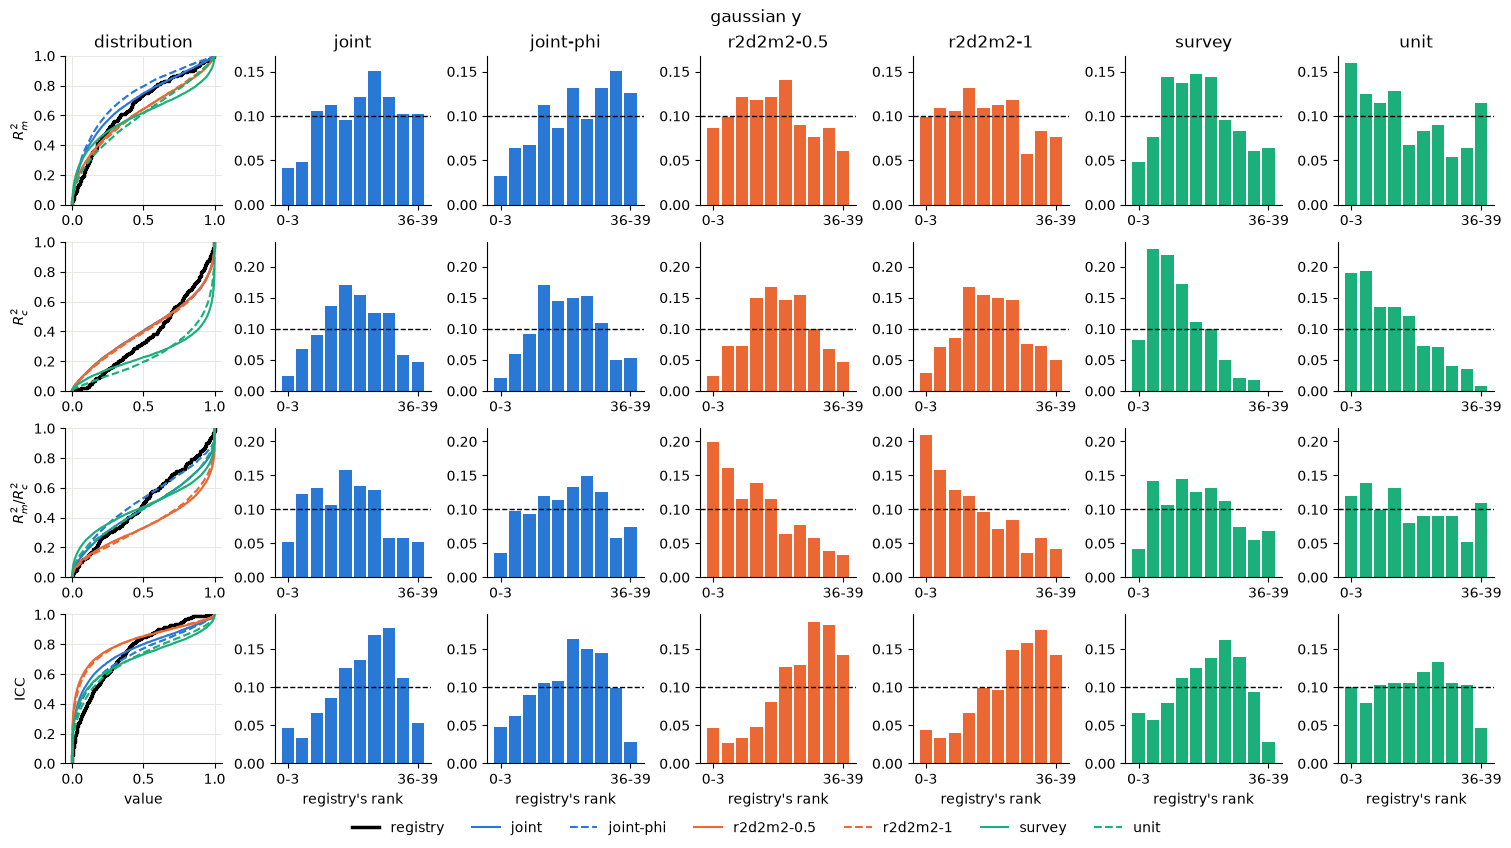

In [9]:
plotRanks('gaussian')

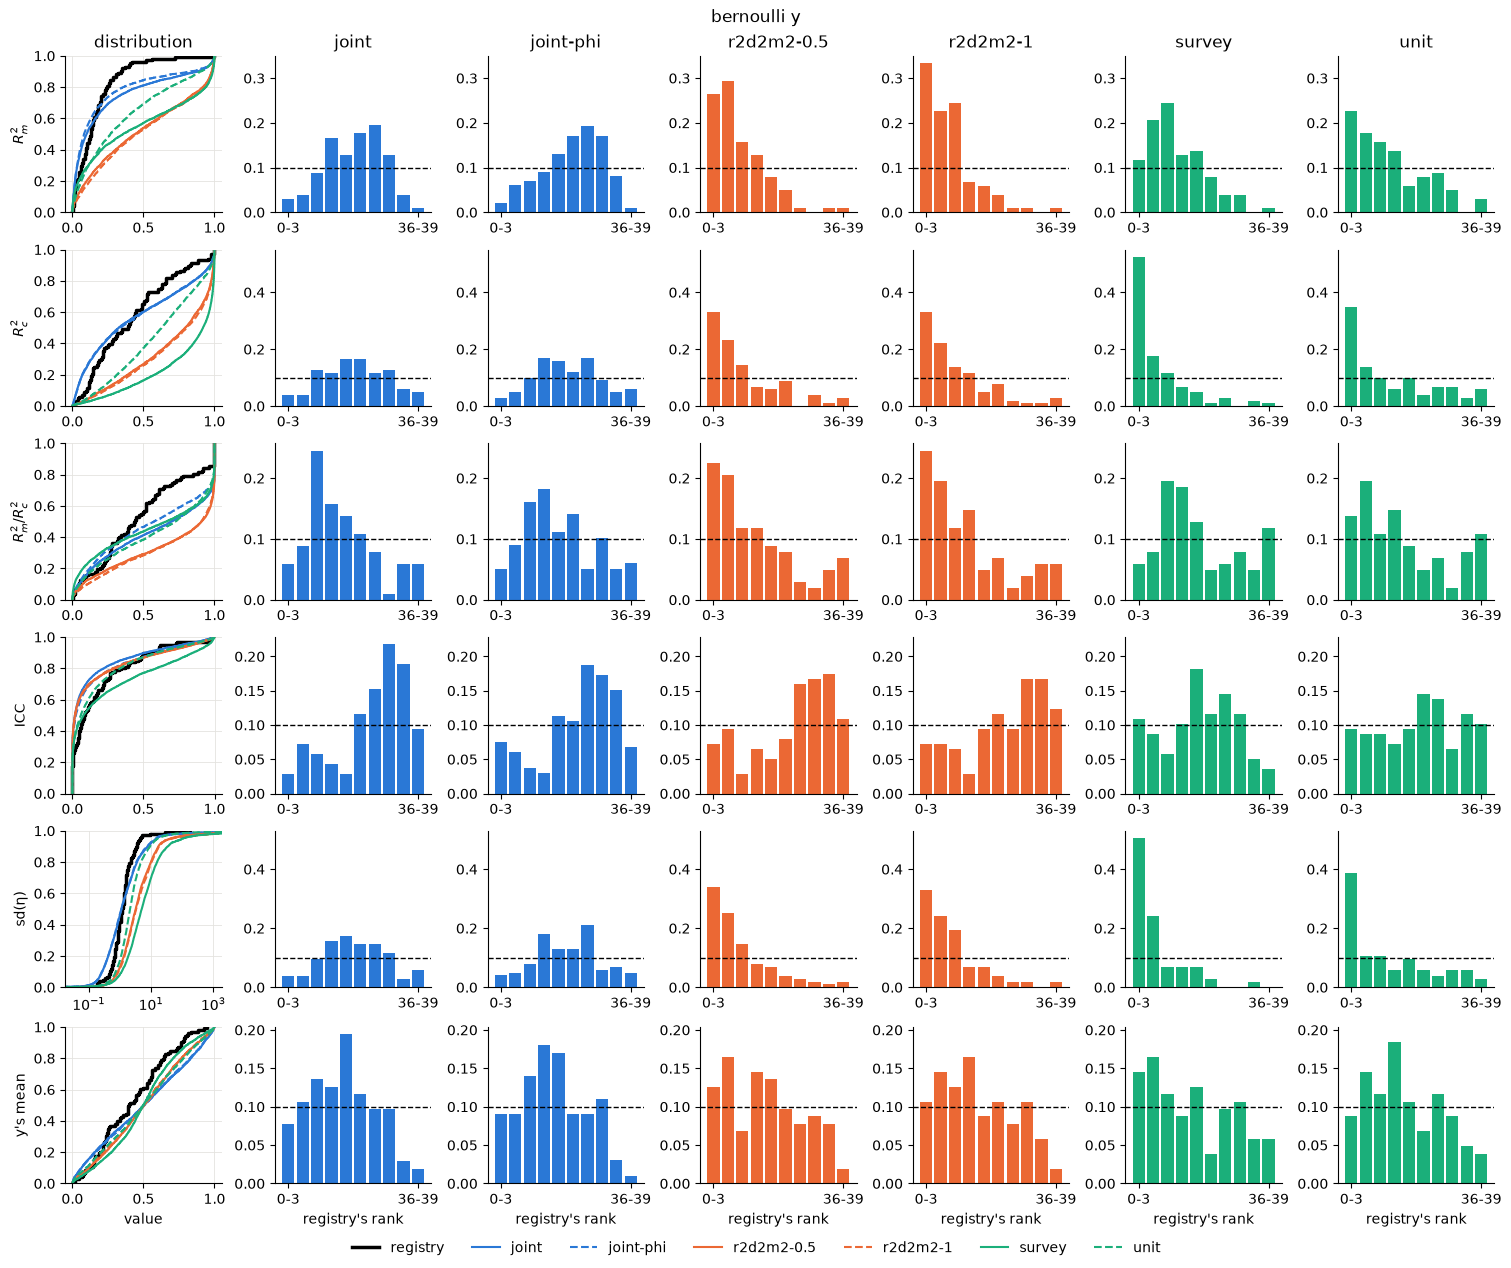

In [10]:
plotRanks('bernoulli')

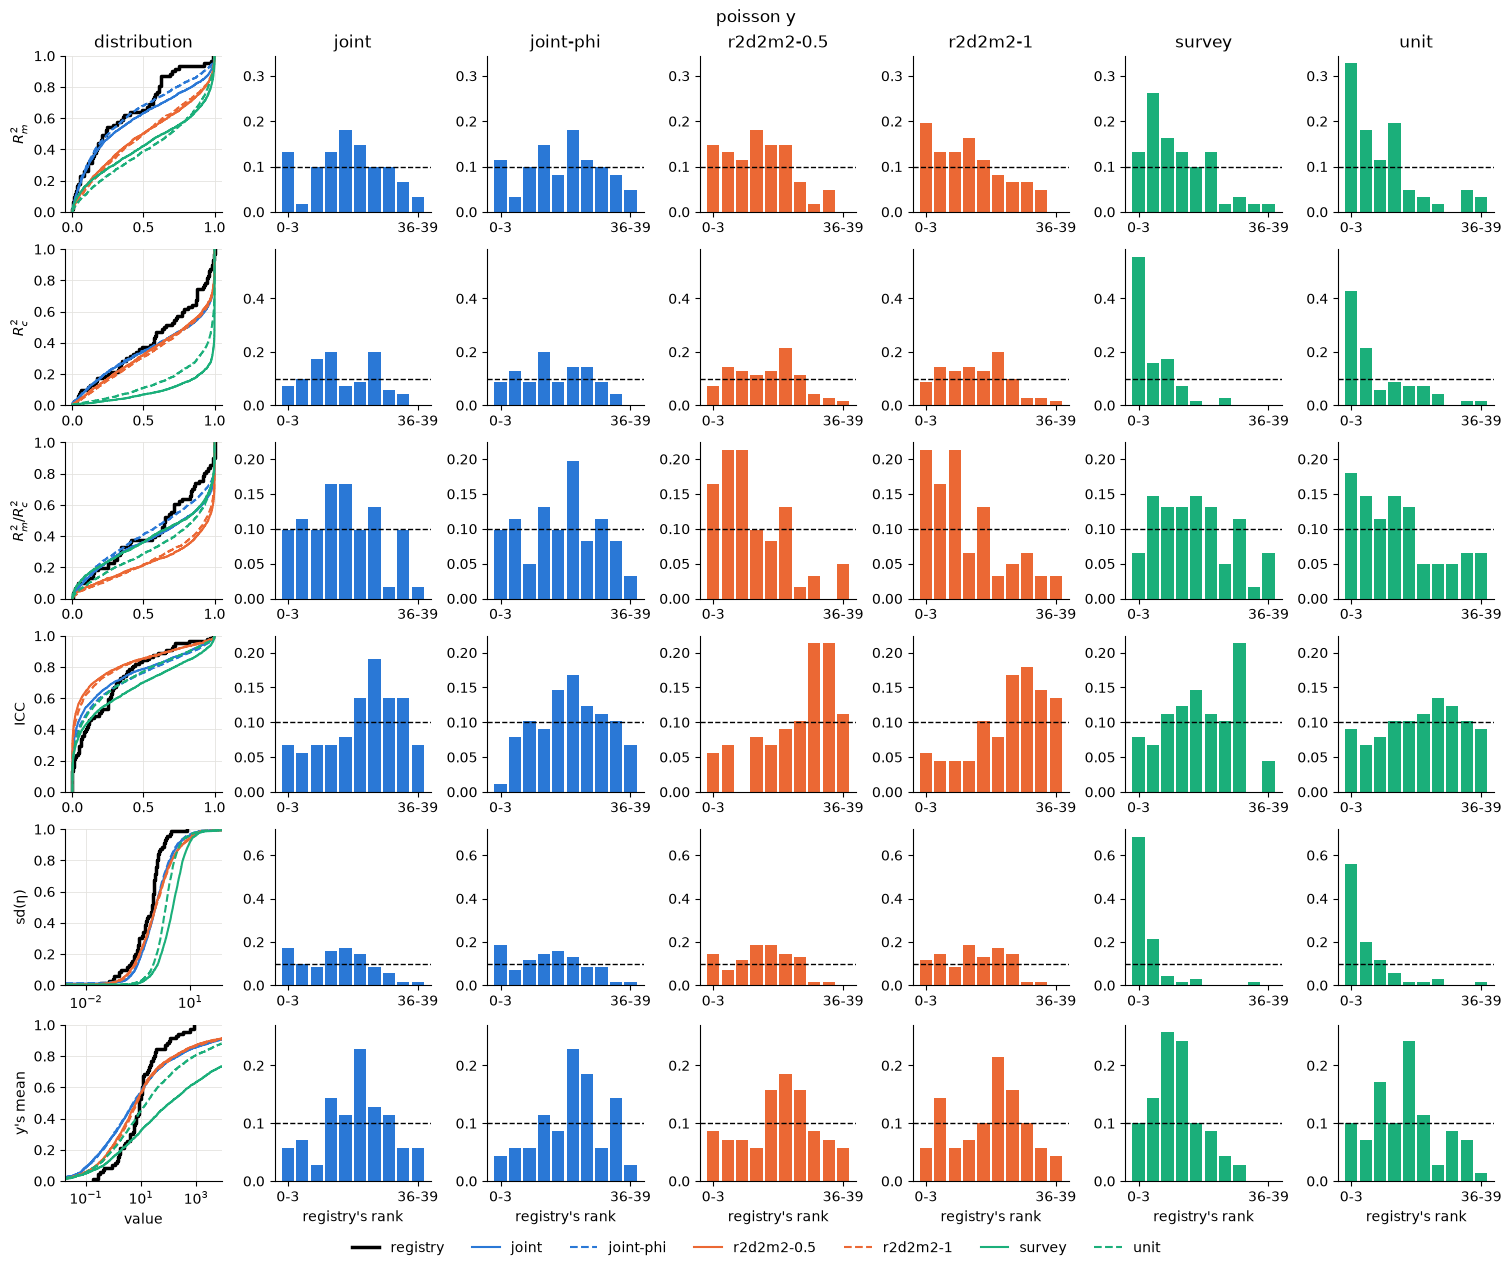

In [11]:
plotRanks('poisson')

## 7. Outside, containment and distance

Per family, measure and prior:
- **outside:** the share of registry fits outside the refits' range.
- **expected:** that share if the ranks are uniform.
- **vs joint:** the paired difference to the joint prior's share outside, with its 95 % interval.
- **distance:** the Wasserstein-1 distance between the registry and the refits.
- **refits in:** the share of refits inside the registry's band.
- **registry in:** the share of registry fits inside the refits' band.

In [12]:
def intervalClustered(difference: pd.Series) -> tuple[float, float]:
    # the mean's 95 % interval by the normal approximation, clustered by fit
    residuals = (difference - difference.mean()).groupby(level='task').sum()  # (fits,)
    clusters = len(residuals)
    variance = (residuals**2).sum() * clusters / (clusters - 1) / len(difference) ** 2
    half = 1.96 * math.sqrt(variance)
    return difference.mean() - half, difference.mean() + half


def compareArms(rng: np.random.Generator) -> pd.DataFrame:
    # a row per family, measure and prior
    outside = ranks.pivot_table(
        index=['family', 'measure', 'task', 'k'], columns='arm', values='outside'
    )
    rows = []
    for family in FAMILIES:
        for measure, label in MEASURES.items():
            in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
            if in_registry.empty:
                continue
            ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
            units = outside.loc[(family, measure)]
            for arm in ARMS:
                under_arm = refits[
                    (refits['family'] == family)
                    & (refits['measure'] == measure)
                    & (refits['arm'] == arm)
                ]
                refit_values = under_arm['value'].to_numpy()[:, None]  # (s, 1)
                # the registry's fits the prior ran on, and the fits it shares with the joint prior
                on_fits = in_registry[in_registry['task'].isin(under_arm['task'])]
                registry_values = on_fits['value'].to_numpy()[:, None]  # (s, 1)
                difference = (units[arm] - units['joint']).dropna()
                [distance] = fidelity.distances(registry_values, refit_values, rng, permutations=0)
                low, high = math.nan, math.nan
                if arm != 'joint':
                    low, high = intervalClustered(difference)
                rows.append(
                    {
                        'family': family,
                        'measure': label,
                        'arm': arm,
                        'outside': units[arm].mean(),
                        'expected': ranked[ranked['arm'] == arm]['expected'].mean(),
                        'vs joint': difference.mean(),
                        'low': low,
                        'high': high,
                        'distance': distance.statistic,
                        'refits in': fidelity.containment(refit_values, registry_values).per_axis[
                            0
                        ],
                        'registry in': fidelity.containment(registry_values, refit_values).per_axis[
                            0
                        ],
                    }
                )
    return pd.DataFrame(rows).set_index(['family', 'measure', 'arm'])


comparison = compareArms(np.random.default_rng(SEED))
for family in FAMILIES:
    print(comparison.loc[family].round(3).to_string(), end='\n\n')

                            outside  expected  vs joint    low   high  distance  refits in  registry in
measure         arm                                                                                    
$R^2_m$         joint         0.040      0.05     0.000    NaN    NaN     0.054      0.983        0.978
                joint-phi     0.047      0.05     0.006 -0.014  0.026     0.088      0.987        0.971
                r2d2m2-0.5    0.062      0.05     0.022 -0.000  0.045     0.052      0.968        0.990
                r2d2m2-1      0.042      0.05     0.002 -0.018  0.022     0.050      0.974        0.990
                survey        0.026      0.05    -0.014 -0.037  0.010     0.083      0.921        0.994
                unit          0.078      0.05     0.038  0.012  0.064     0.063      0.973        0.987
$R^2_c$         joint         0.018      0.05     0.000    NaN    NaN     0.070      0.909        0.994
                joint-phi     0.009      0.05    -0.009 -0.024  

In [13]:
# the measures the joint prior loses: it leaves more fits outside than uniform ranks would,
# and another prior leaves fewer, at no larger distance
joint_comparison = comparison.xs('joint', level='arm')
others = comparison.drop(index='joint', level='arm')
per_measure = others.index.droplevel('arm')
misses = joint_comparison['outside'] > joint_comparison['expected']
misses = misses.reindex(per_measure).to_numpy()
no_larger = others['distance'] <= joint_comparison['distance'].reindex(per_measure).to_numpy()
losses = others[misses & (others['high'] < 0) & no_larger]
if losses.empty:
    print('none')
else:
    print(losses[['outside', 'vs joint', 'high', 'distance']].round(3).to_string())

none


## 8. Singular fits and the slope over d

In [14]:
# the share of singular fits among the fits with estimates, in the registry and under each prior
fitted = records[records['fit_status'].isin(ESTIMATED)]
singular = (fitted['fit_status'] == 'singular').groupby([fitted['family'], fitted['arm']]).mean()
singular = singular.unstack()
singular.insert(0, 'registry', (tasks['status'] == 'singular').groupby(tasks['family']).mean())
print(singular.loc[FAMILIES].round(3).to_string())

arm        registry  joint  joint-phi  r2d2m2-0.5  r2d2m2-1  survey   unit
family                                                                    
gaussian      0.082  0.238      0.213       0.286     0.257   0.165  0.147
bernoulli     0.233  0.310      0.293       0.263     0.239   0.162  0.209
poisson       0.114  0.231      0.209       0.294     0.252   0.104  0.138


In [15]:
def fitSlope(d: pd.Series, r2: pd.Series) -> dict[str, float]:
    # OLS of R²_m on log₂ d, its slope's 95 % interval by the normal approximation
    centered = np.log2(d) - np.log2(d).mean()
    slope = (centered * r2).sum() / (centered**2).sum()
    residuals = r2 - r2.mean() - slope * centered
    se = math.sqrt((residuals**2).sum() / (len(r2) - 2) / (centered**2).sum())
    return {'slope': slope, 'low': slope - 1.96 * se, 'high': slope + 1.96 * se, 'fits': len(r2)}


slopes = {}
for family in FAMILIES:
    in_registry = real[(real['family'] == family) & (real['measure'] == 'r2_marginal')]
    slopes[(family, 'registry')] = fitSlope(in_registry['rank'], in_registry['value'])
    under_arms = refits[(refits['family'] == family) & (refits['measure'] == 'r2_marginal')]
    for arm in ARMS:
        per_fit = under_arms[under_arms['arm'] == arm].groupby('task')[['rank', 'value']].mean()
        slopes[(family, arm)] = fitSlope(per_fit['rank'], per_fit['value'])
print(pd.DataFrame(slopes).T.round(3).to_string())

                      slope    low   high   fits
gaussian  registry    0.014 -0.016  0.043  313.0
          joint       0.031  0.025  0.038  313.0
          joint-phi   0.031  0.025  0.037  311.0
          r2d2m2-0.5  0.098  0.089  0.106  313.0
          r2d2m2-1    0.095  0.086  0.104  313.0
          survey      0.082  0.069  0.095  313.0
          unit        0.101  0.086  0.117  313.0
bernoulli registry    0.067  0.033  0.102  102.0
          joint       0.041  0.018  0.064  102.0
          joint-phi   0.045  0.021  0.069   99.0
          r2d2m2-0.5  0.122  0.096  0.148  102.0
          r2d2m2-1    0.125  0.099  0.152  102.0
          survey      0.097  0.069  0.124  102.0
          unit        0.131  0.102  0.159  102.0
poisson   registry    0.132  0.021  0.243   61.0
          joint       0.040  0.009  0.071   61.0
          joint-phi   0.035  0.006  0.064   61.0
          r2d2m2-0.5  0.132  0.102  0.162   61.0
          r2d2m2-1    0.144  0.115  0.173   61.0
          survey    

## 9. Saturation

A link saturates when some |η| is so large that y is all but fixed at a row, as on a separated Bernoulli fit.<br>
lme4's max |η̂| reads it off a fit, so the real y and the drawn ones are measured alike.<br>
The registry records no max |η̂|, so each real y was refitted once, on the same machine as the drawn ones.

In [16]:
# the share of fits with some |η̂| above 10 on the logit and log links, the real y's and each prior's
LINKS = ['bernoulli', 'poisson']
real_refits = pd.read_csv('registry-real.csv').merge(tasks[['task', 'family']], on='task')
real_fitted = real_refits[real_refits['status'].isin(ESTIMATED)]
saturated = (fitted['fit_max_abs_eta'] > 10).groupby([fitted['family'], fitted['arm']]).mean()
saturated = saturated.unstack()
in_registry = (real_fitted['max_abs_eta'] > 10).groupby(real_fitted['family']).mean()
saturated.insert(0, 'registry', in_registry)
print(saturated.loc[LINKS].round(3).to_string())

arm        registry  joint  joint-phi  r2d2m2-0.5  r2d2m2-1  survey   unit
family                                                                    
bernoulli     0.107  0.244      0.234       0.506     0.528   0.623  0.366
poisson       0.014  0.221      0.201       0.242     0.246   0.535  0.322


### Check: the real refit against the registry's fit

The real refit repeats the registry's fit, so its status and sd(η̂) should match the registry's.<br>
A separated fit has its maximum likelihood at infinity, so lme4 stops wherever its tolerance trips.<br>
There, sd(η̂) moves with the machine's linear algebra library.

In [17]:
# the real refits whose status differs from the registry's, or whose sd(η̂) differs by over 1 %
check = real_refits.set_index('task')
check['registry_status'] = tasks.set_index('task')['status']
check['registry_sd_eta'] = real[real['measure'] == 'sd_eta'].set_index('task')['value']
apart = (check['sd_eta'] / check['registry_sd_eta'] - 1).abs() > 0.01
differ = check[(check['status'] != check['registry_status']) | apart]
print(f'{len(differ)} of {len(check)} real refits differ from the registry')
columns = ['family', 'registry_status', 'status', 'registry_sd_eta', 'sd_eta', 'max_abs_eta']
print(differ[columns].round(2).to_string())

0 of 515 real refits differ from the registry
Empty DataFrame
Columns: [family, registry_status, status, registry_sd_eta, sd_eta, max_abs_eta]
Index: []


## 10. The joint prior split by its draws

Ranking a registry fit among only the joint refits whose draw falls in one bin ranks it under the joint prior restricted to that bin.<br>
So a bin previews a changed default without a rerun.
- **Tilt:** the mean normalized rank (r + V) / (m + 1) over the fits, its expectation over V and the tie-break.
- **0.5:** the restricted prior fits real tables.
- **Above 0.5:** the bin's refits run below the registry.
- **Interval:** ±1.96 standard errors, clustered by fit, for a bin of two fits or more.
- **Draws of the fit:** φ, Xβ's share of the predictor's variance, the intercept's location ν₀ and scale τ₀, and the predictor's sd τ, which split every measure.
- **τ on a Gaussian y:** set by the drawn R² and σ_ε, not drawn itself.
- **Draws of a factor:** its share of the predictor's variance, the spread of its σ_α scales (the sd of their logs) and its LKJ shape, which split only that factor's ICC.
- **Bins:** the joint draws' quartiles per family, a draw of 0 apart (φ without slopes, the spread of a lone or shared scale), and the LKJ shape by value, `none` for a factor without correlations.
- **m:** the mean number of refits per fit in the bin.
- **singular and saturated:** the shares of singular refits and of refits with some |η̂| above 10 in the bin, binned by the smallest value among a fit's factors for a factor's draw.

In [18]:
FIT_DRAWS = {
    'split_fixed': 'φ',
    'intercept_location': 'ν₀',
    'intercept_scale': 'τ₀',
    'predictor_sd': 'τ',
}
FACTOR_DRAWS = {
    'split': "factor's share",
    'sigma_alpha_spread': 'σ_α spread',
    'lkj_eta': 'LKJ shape',
}
ZERO_APART = ['split_fixed', 'sigma_alpha_spread']  # the draws that are 0 by construction
joint = records[records['arm'] == 'joint']

# a row per joint draw and factor of its fit
parts = []
for k in range(1, tasks['factors'].max() + 1):
    part = joint[['task', 'draw', 'family']].assign(k=k)
    for name in FACTOR_DRAWS:
        part[name] = joint[f'{name}_{k}']
    parts.append(part)
factor_draws = pd.concat(parts)
factor_draws = factor_draws[factor_draws['split'].notna()]  # NaN past the fit's factors

# a fit is singular or saturated as a whole, so it takes the smallest value among its factors
# (the lowest LKJ shape among its correlated factors, none without one)
smallest = factor_draws.groupby(['task', 'draw', 'family'], as_index=False)[
    list(FACTOR_DRAWS)
].min()


def binQuartiles(values: pd.Series, reference: pd.Series) -> pd.Series:
    # the reference draws' quartiles, labelled in order by their range
    edges = np.unique(reference.quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy())
    labels = []
    for i in range(len(edges) - 1):
        labels.append(f'{i + 1}: {edges[i]:.2f} to {edges[i + 1]:.2f}')
    return pd.cut(values, edges, labels=labels, include_lowest=True).astype(object)


def binDraws(table: pd.DataFrame, name: str, reference: pd.DataFrame) -> pd.Series:
    # each row's bin of the draw `name`, per family at the reference draws' quartiles
    if name == 'lkj_eta':
        return table[name].map('{:.0f}'.format, na_action='ignore').fillna('none')
    bins = pd.Series(index=table.index, dtype=object)
    for family in FAMILIES:
        rows = table['family'] == family
        family_reference = reference[reference['family'] == family][name]
        if name in ZERO_APART:
            family_reference = family_reference[family_reference != 0]
        bins[rows] = binQuartiles(table[rows][name], family_reference)
    if name in ZERO_APART:
        bins[table[name] == 0] = '0: 0'
    return bins


def tiltPerBin(paired: pd.DataFrame) -> pd.DataFrame:
    # each fit's normalized rank among the bin's refits, then its mean over fits per family,
    # measure and bin, with the 95 % interval's half width
    units = paired.groupby(['family', 'measure', 'bin', 'task', 'k'], as_index=False).agg(
        below=('below', 'sum'), tied=('tied', 'sum'), m=('value', 'size')
    )
    units['rank'] = (units['below'] + units['tied'] / 2 + 0.5) / (units['m'] + 1)
    rows = []
    for (family, measure, bin), table in units.groupby(['family', 'measure', 'bin']):
        if table['task'].nunique() < 2:
            continue  # a bin of one fit has no interval clustered by fit
        low, high = intervalClustered(table.set_index('task')['rank'])
        tilt = {'tilt': table['rank'].mean(), 'half': (high - low) / 2, 'm': table['m'].mean()}
        rows.append({'family': family, 'measure': MEASURES[measure], 'bin': bin} | tilt)
    return pd.DataFrame(rows)


def showSplit(name: str) -> None:
    # the tilt per family and bin of one draw, with the bin's singular and saturated shares
    if name in FIT_DRAWS:
        bins = binDraws(joint, name, joint)
        draws = joint[['task', 'draw']].assign(bin=bins)
        paired = joint_paired.merge(draws, on=['task', 'draw'])
        fit_bins = draws
    else:
        bins = binDraws(factor_draws, name, factor_draws)
        draws = factor_draws[['task', 'draw', 'k']].assign(bin=bins)
        paired = joint_paired.merge(draws, on=['task', 'draw', 'k'])
        fit_bins = smallest[['task', 'draw']].assign(bin=binDraws(smallest, name, factor_draws))
    tilts = tiltPerBin(paired)
    tilts['cell'] = tilts['tilt'].map('{:.2f}'.format) + ' ±' + tilts['half'].map('{:.2f}'.format)
    table = tilts.pivot_table(
        index=['family', 'bin'], columns='measure', values='cell', aggfunc='first'
    )
    measures = []
    for label in MEASURES.values():
        if label in table.columns:
            measures.append(label)
    table = table[measures]
    table['m'] = tilts.groupby(['family', 'bin'])['m'].mean().round(1)

    # the singular and saturated shares among the bin's joint refits with estimates
    estimated = joint[joint['fit_status'].isin(ESTIMATED)].merge(fit_bins, on=['task', 'draw'])
    groups = [estimated['family'], estimated['bin']]
    table['singular'] = (estimated['fit_status'] == 'singular').groupby(groups).mean().round(3)
    on_links = estimated['family'].isin(LINKS)
    saturated = (estimated['fit_max_abs_eta'] > 10).where(on_links)
    table['saturated'] = saturated.groupby(groups).mean().round(3)
    print(f'{FIT_DRAWS.get(name) or FACTOR_DRAWS[name]}')
    print(table.loc[FAMILIES].to_string(), end='\n\n')


joint_paired = pairRegistry()
joint_paired = joint_paired[joint_paired['arm'] == 'joint']
registry_singular = (tasks['status'] == 'singular').groupby(tasks['family']).mean()
print(f'singular in the registry: {registry_singular.round(3).to_dict()}', end='\n\n')
for name in [*FIT_DRAWS, *FACTOR_DRAWS]:
    showSplit(name)

singular in the registry: {'bernoulli': 0.233, 'gaussian': 0.082, 'poisson': 0.114}

φ
measure                       $R^2_m$     $R^2_c$ $R^2_m / R^2_c$         ICC       sd(η)    y's mean     m  singular saturated
family    bin                                                                                                                  
gaussian  0: 0                    NaN  0.54 ±0.08             NaN  0.55 ±0.06         NaN         NaN  39.0     0.210       NaN
          1: 0.00 to 0.25  0.73 ±0.03  0.52 ±0.03      0.65 ±0.03  0.44 ±0.02         NaN         NaN   9.7     0.209       NaN
          2: 0.25 to 0.50  0.58 ±0.03  0.50 ±0.03      0.51 ±0.03  0.52 ±0.02         NaN         NaN   9.7     0.211       NaN
          3: 0.50 to 0.75  0.49 ±0.03  0.49 ±0.03      0.40 ±0.03  0.58 ±0.03         NaN         NaN   9.8     0.231       NaN
          4: 0.75 to 1.00  0.42 ±0.03  0.52 ±0.03      0.29 ±0.03  0.71 ±0.02         NaN         NaN   9.8     0.312       NaN
bernoulli 1: 0.00

ν₀


measure                         $R^2_m$     $R^2_c$ $R^2_m / R^2_c$         ICC       sd(η)    y's mean     m  singular saturated
family    bin                                                                                                                    
gaussian  1: -3.00 to -1.48  0.56 ±0.03  0.52 ±0.02      0.47 ±0.03  0.56 ±0.02         NaN         NaN   9.8     0.239       NaN
          2: -1.48 to -0.01  0.55 ±0.03  0.51 ±0.03      0.46 ±0.03  0.56 ±0.02         NaN         NaN   9.8     0.231       NaN
          3: -0.01 to 1.48   0.55 ±0.03  0.51 ±0.02      0.47 ±0.03  0.56 ±0.02         NaN         NaN   9.7     0.247       NaN
          4: 1.48 to 3.00    0.55 ±0.03  0.52 ±0.02      0.46 ±0.03  0.57 ±0.02         NaN         NaN   9.8     0.235       NaN
bernoulli 1: -3.00 to -1.44  0.47 ±0.04  0.49 ±0.05      0.40 ±0.05  0.62 ±0.04  0.48 ±0.05  0.70 ±0.05   9.7     0.318     0.252
          2: -1.44 to 0.07   0.54 ±0.05  0.53 ±0.04      0.43 ±0.05  0.62 ±0.04  0.53 ±0.

τ₀
measure                        $R^2_m$     $R^2_c$ $R^2_m / R^2_c$         ICC       sd(η)    y's mean     m  singular saturated
family    bin                                                                                                                   
gaussian  1: 0.10 to 0.32   0.56 ±0.03  0.52 ±0.02      0.47 ±0.03  0.56 ±0.02         NaN         NaN   9.8     0.234       NaN
          2: 0.32 to 1.02   0.57 ±0.03  0.51 ±0.03      0.48 ±0.03  0.55 ±0.02         NaN         NaN   9.7     0.236       NaN
          3: 1.02 to 3.19   0.54 ±0.03  0.50 ±0.03      0.46 ±0.03  0.56 ±0.02         NaN         NaN   9.8     0.240       NaN
          4: 3.19 to 10.00  0.55 ±0.03  0.51 ±0.02      0.45 ±0.03  0.57 ±0.02         NaN         NaN   9.7     0.243       NaN
bernoulli 1: 0.10 to 0.33   0.53 ±0.04  0.54 ±0.05      0.42 ±0.05  0.61 ±0.04  0.54 ±0.05  0.40 ±0.05  10.4     0.281     0.187
          2: 0.33 to 1.00   0.53 ±0.04  0.54 ±0.05      0.44 ±0.05  0.61 ±0.04  0.53 ±0.04  0.

τ
measure                       $R^2_m$     $R^2_c$ $R^2_m / R^2_c$         ICC       sd(η)    y's mean     m  singular saturated
family    bin                                                                                                                  
gaussian  1: 0.06 to 0.57  0.65 ±0.03  0.65 ±0.02      0.46 ±0.03  0.63 ±0.02         NaN         NaN   9.8     0.312       NaN
          2: 0.57 to 0.71  0.57 ±0.03  0.57 ±0.03      0.46 ±0.03  0.58 ±0.02         NaN         NaN   9.7     0.246       NaN
          3: 0.71 to 0.82  0.53 ±0.03  0.48 ±0.03      0.46 ±0.03  0.55 ±0.02         NaN         NaN   9.8     0.224       NaN
          4: 0.82 to 1.00  0.47 ±0.03  0.35 ±0.02      0.47 ±0.03  0.50 ±0.02         NaN         NaN   9.8     0.170       NaN
bernoulli 1: 0.25 to 0.50  0.71 ±0.04  0.75 ±0.04      0.39 ±0.05  0.75 ±0.04  0.76 ±0.04  0.46 ±0.05   9.6     0.477     0.139
          2: 0.50 to 1.00  0.58 ±0.05  0.63 ±0.05      0.42 ±0.05  0.66 ±0.04  0.63 ±0.05  0.42 ±0.04 

LKJ shape
measure                ICC     m  singular saturated
family    bin                                       
gaussian  1     0.54 ±0.07  10.1     0.466       NaN
          2     0.55 ±0.06   9.7     0.384       NaN
          3     0.54 ±0.07   9.0     0.434       NaN
          4     0.55 ±0.07  10.1     0.375       NaN
          none  0.57 ±0.02  39.0     0.203       NaN
bernoulli 1     0.66 ±0.11   7.9     0.275     0.297
          2     0.60 ±0.13  10.5     0.157     0.322
          3     0.60 ±0.15   9.0     0.178     0.256
          4     0.56 ±0.16  11.6     0.149     0.362
          none  0.63 ±0.04  39.0     0.323     0.237
poisson   1     0.55 ±0.40  12.0     0.333     0.208
          2     0.45 ±0.51  15.0     0.200     0.167
          3     0.62 ±0.37   7.0     0.357     0.071
          4     0.42 ±0.33   5.0     0.100       0.2
          none  0.56 ±0.05  39.0     0.230     0.222



## 11. Candidate defaults by reweighting

Section 10 restricts the joint prior to one bin of one draw.<br>
Importance sampling (IS) scores a whole candidate prior on the joint refits instead, without a rerun.<br>
Each joint draw is weighted by the candidate's density over the joint prior's at what it drew.<br>
Since the other draws do not depend on these, the weighted refits are the candidate's.

The candidates move the draws that section 10 ties to the lean.
- **φ:** Beta(1, 1) by default, the ICC's knob.
- **τ₀:** LogUniform(0.1, 10) by default, a knob of saturation.
- **τ:** LogUniform(0.25, 4) by default on the logit and log links, the stronger knob of saturation.
- **Unmoved draws:** weight 1, φ on a fit without slopes and τ on a Gaussian y.
- **Candidates:** φ pulled below 0.5, τ₀ and τ with a lower top, each alone and together.
- **Added after the first run:** φ ~ Beta(2, 3) with τ₀ to 3, the pair without τ, which the first seven left out.

In [19]:
# each candidate as its Glmm fields' overrides
CANDIDATES = {
    'joint': {},
    'φ Beta(1, 2)': {'fixed_share': Beta(1, 2)},
    'φ Beta(2, 3)': {'fixed_share': Beta(2, 3)},
    'τ₀ to 3': {'intercept_scale': LogUniform(0.1, 3)},
    'τ to 2': {'predictor_sd': LogUniform(0.25, 2)},
    'τ₀ to 3, τ to 2': {
        'intercept_scale': LogUniform(0.1, 3),
        'predictor_sd': LogUniform(0.25, 2),
    },
    'φ Beta(1, 2), τ₀ to 3, τ to 2': {
        'fixed_share': Beta(1, 2),
        'intercept_scale': LogUniform(0.1, 3),
        'predictor_sd': LogUniform(0.25, 2),
    },
    'φ Beta(2, 3), τ₀ to 3, τ to 2': {
        'fixed_share': Beta(2, 3),
        'intercept_scale': LogUniform(0.1, 3),
        'predictor_sd': LogUniform(0.25, 2),
    },
    'φ Beta(2, 3), τ₀ to 3': {'fixed_share': Beta(2, 3), 'intercept_scale': LogUniform(0.1, 3)},
}


def weighDraws(candidate: dict[str, Beta | LogUniform], draws: pd.DataFrame) -> pd.Series:
    # each draw's weight, the candidate's density over Glmm's default's at what the prior drew,
    # for a candidate that moves only fields the prior draws at their defaults
    weights = pd.Series(1.0, index=draws.index)
    for field, distribution in candidate.items():
        drawn = readDraws(field, draws)
        default = Glmm.model_fields[field].default
        ratio = density(distribution, drawn) / density(default, drawn)
        weights = weights * ratio.fillna(1.0)
    return weights


def readDraws(field: str, draws: pd.DataFrame) -> pd.Series:
    # each draw of a field, NaN where it moves nothing:
    # φ on a fit without slopes, τ on a Gaussian y, where it follows from R² and σ_ε
    match field:
        case 'fixed_share':
            return draws['split_fixed'].where(draws['split_fixed'] > 0)
        case 'intercept_scale':
            return draws['intercept_scale']
        case 'predictor_sd':
            return draws['predictor_sd'].where(draws['family'] != 'gaussian')


def density(distribution: Beta | LogUniform, values: pd.Series) -> pd.Series:
    # a field's distribution's density at the draws
    match distribution:
        case Beta(a=a, b=b):
            out = stats.beta(a, b).pdf(values)
        case LogUniform(low=low, high=high):
            out = stats.loguniform(low, high).pdf(values)
    return pd.Series(out, index=values.index)


weights = {}
for name, candidate in CANDIDATES.items():
    weights[name] = weighDraws(candidate, joint)

Per fit and factor, a candidate's weighted refits give four numbers.
- **F̂:** the weighted share of refits below the registry's estimate, ties halved.
- **ESS:** the Kish effective sample size (Σw)² / Σw², 39 under the joint prior.
- **Tilt:** (ESS · F̂ + 0.5) / (ESS + 1), section 10's tilt at weight 1.
- **Outside:** the chance that 39 new refits leave the registry outside their range, F³⁹ + (1 - F)³⁹, averaged over F ~ Beta(ESS · F̂ + 1, ESS · (1 - F̂) + 1).

The average matters, since F̂ rests on 39 refits at most.<br>
F̂³⁹ + (1 - F̂)³⁹ alone gives 7.8 % at uniform ranks, the average exactly 2/40 = 5 %, and it widens as the ESS falls.<br>
At weight 1 it differs from section 7's share outside fit by fit, so the joint prior is scored here by the same rule as each candidate.
- **outside:** the mean over the fits and factors.
- **vs joint:** the paired difference to the joint prior's, with its 95 % interval clustered by fit.

In [20]:
UNIT = [
    'family',
    'measure',
    'task',
    'k',
]  # a registry fit's factor, k = 0 for the fit's own measure


every_paired = pairRegistry()  # every prior's refits beside the registry's estimates


def scoreRegistry(draw_weights: pd.Series) -> pd.DataFrame:
    # per fit, measure and factor: the weighted share F̂ of one prior's refits below the registry,
    # the tilt and the chance to fall outside 39 new refits, the weights indexed by its records
    weighted = records.loc[draw_weights.index, ['task', 'draw', 'arm']].assign(weight=draw_weights)
    paired = every_paired.merge(weighted, on=['task', 'draw', 'arm'])
    paired['weight_below'] = paired['weight'] * (paired['below'] + paired['tied'] / 2)
    paired['weight_squared'] = paired['weight'] ** 2
    units = paired.groupby(UNIT, as_index=False).agg(
        weight=('weight', 'sum'), below=('weight_below', 'sum'), squared=('weight_squared', 'sum')
    )
    share = units['below'] / units['weight']  # F̂
    ess = units['weight'] ** 2 / units['squared']
    units['tilt'] = (ess * share + 0.5) / (ess + 1)
    units['outside'] = expectOutside(ess * share + 1, ess * (1 - share) + 1)
    return units


def expectOutside(a: pd.Series, b: pd.Series) -> pd.Series:
    # E[F^m + (1 - F)^m] for F ~ Beta(a, b), as E[F^m] = B(a + m, b) / B(a, b)
    log_normalizer = special.betaln(a, b)
    all_below = np.exp(special.betaln(a + REFITS, b) - log_normalizer)
    all_above = np.exp(special.betaln(a, b + REFITS) - log_normalizer)
    return all_below + all_above


def compareMeasures(scores: dict[str, pd.DataFrame]) -> pd.DataFrame:
    # a row per family, measure and candidate
    joint_outside = scores['joint'].set_index(UNIT)['outside']
    rows = []
    for family in FAMILIES:
        for measure, label in MEASURES.items():
            for name, scored in scores.items():
                part = scored[(scored['family'] == family) & (scored['measure'] == measure)]
                if part.empty:
                    continue
                part = part.set_index(UNIT)
                difference = part['outside'] - joint_outside.reindex(part.index)
                low, high = math.nan, math.nan
                if name != 'joint':
                    low, high = intervalClustered(difference)
                rows.append(
                    {
                        'family': family,
                        'measure': label,
                        'candidate': name,
                        'tilt': part['tilt'].mean(),
                        'outside': part['outside'].mean(),
                        'vs joint': difference.mean(),
                        'low': low,
                        'high': high,
                    }
                )
    return pd.DataFrame(rows).set_index(['family', 'measure', 'candidate'])


scores = {}
for name, draw_weights in weights.items():
    scores[name] = scoreRegistry(draw_weights)
measures = compareMeasures(scores)
for family in FAMILIES:
    print(measures.loc[family].round(3).to_string(), end='\n\n')

                                                tilt  outside  vs joint    low   high
measure         candidate                                                            
$R^2_m$         joint                          0.559    0.040     0.000    NaN    NaN
                φ Beta(1, 2)                   0.632    0.051     0.011  0.006  0.016
                φ Beta(2, 3)                   0.588    0.050     0.010  0.005  0.015
                τ₀ to 3                        0.560    0.042     0.001 -0.003  0.006
                τ to 2                         0.559    0.040     0.000  0.000  0.000
                τ₀ to 3, τ to 2                0.560    0.042     0.001 -0.003  0.006
                φ Beta(1, 2), τ₀ to 3, τ to 2  0.632    0.050     0.010  0.004  0.016
                φ Beta(2, 3), τ₀ to 3, τ to 2  0.588    0.050     0.010  0.004  0.017
                φ Beta(2, 3), τ₀ to 3          0.588    0.050     0.010  0.004  0.017
$R^2_c$         joint                          0.514  

Per fit, the weights also move the shares of section 5, 8 and 9.
- **failed:** the weighted share of the fit's draws without estimates.
- **singular:** the weighted share of its refits that lme4 flags as singular.
- **saturated:** the weighted share of its refits with some |η̂| above 10, on the logit and log links.
- **Each share:** the mean over fits, with the paired difference to the joint prior's and its 95 % interval.
- **ESS:** its smallest value and median over the fits, among the refits with estimates.

In [21]:
# per draw of any prior, whether it failed, turned singular or saturated, NaN where unrecorded
with_estimates = records['fit_status'].isin(ESTIMATED)
outcomes = {
    'failed': ~with_estimates,
    'singular': (records['fit_status'] == 'singular').where(with_estimates),
    'saturated': (records['fit_max_abs_eta'] > 10).where(
        with_estimates & records['family'].isin(LINKS)
    ),
}


def shareWeighted(outcome: pd.Series, draw_weights: pd.Series) -> pd.Series:
    # per fit, the weighted share of one prior's draws where the outcome holds,
    # among the draws that record it, the weights indexed by its records
    holds = outcome.loc[draw_weights.index]
    recorded = holds.notna()
    per_task = records.loc[draw_weights.index, 'task'][recorded]
    weighted = holds[recorded].astype(float) * draw_weights[recorded]
    return weighted.groupby(per_task).sum() / draw_weights[recorded].groupby(per_task).sum()  # (fits,)


def compareShares(weights: dict[str, pd.Series]) -> pd.DataFrame:
    # a row per candidate
    families = tasks.set_index('task')['family']
    rows = {}
    for name, draw_weights in weights.items():
        row = {}
        for outcome, holds in outcomes.items():
            per_fit = shareWeighted(holds, draw_weights)
            in_joint = shareWeighted(holds, weights['joint'])
            for family, share in per_fit.groupby(families):
                row[(family, outcome, 'share')] = share.mean()
                if outcome == 'failed':
                    continue
                difference = share - in_joint.reindex(share.index)
                low, high = math.nan, math.nan
                if name != 'joint':
                    low, high = intervalClustered(difference)
                row[(family, outcome, 'vs joint')] = difference.mean()
                row[(family, outcome, 'low')] = low
                row[(family, outcome, 'high')] = high

        # the ESS per fit among the draws with estimates
        among = draw_weights[with_estimates.loc[draw_weights.index]]
        per_task = records.loc[among.index, 'task']
        ess = among.groupby(per_task).sum() ** 2 / (among**2).groupby(per_task).sum()
        for family, per_family in ess.groupby(families):
            row[(family, 'ESS', 'min')] = per_family.min()
            row[(family, 'ESS', 'median')] = per_family.median()
        rows[name] = row
    table = pd.DataFrame(rows).T
    table.index.name = 'candidate'
    return table


shares = compareShares(weights)
for family in FAMILIES:
    print(shares[family].dropna(axis=1, how='all').round(3).to_string(), end='\n\n')


                              failed singular                            ESS        
                               share    share vs joint    low   high     min  median
candidate                                                                           
joint                            0.0    0.238    0.000    NaN    NaN  39.000  39.000
φ Beta(1, 2)                     0.0    0.217   -0.021 -0.025 -0.018  23.645  29.615
φ Beta(2, 3)                     0.0    0.218   -0.020 -0.025 -0.016  22.380  28.981
τ₀ to 3                          0.0    0.235   -0.003 -0.007  0.001  19.000  29.000
τ to 2                           0.0    0.238    0.000  0.000  0.000  39.000  39.000
τ₀ to 3, τ to 2                  0.0    0.235   -0.003 -0.007  0.001  19.000  29.000
φ Beta(1, 2), τ₀ to 3, τ to 2    0.0    0.213   -0.025 -0.031 -0.019  13.409  22.082
φ Beta(2, 3), τ₀ to 3, τ to 2    0.0    0.214   -0.024 -0.030 -0.018  11.813  21.345
φ Beta(2, 3), τ₀ to 3            0.0    0.214   -0.024 -0.030 -0.

A candidate wins when three things hold.
- **ICC:** its tilt lies closer to 0.5 than the joint prior's on every family.
- **Fewer singular or saturated fits:** on some family, with the paired difference's 95 % interval below 0.
- **No new miss:** no measure the joint prior leaves at most 2/40 outside goes above it.
- **margin:** 2/40 minus the largest share outside among those measures.

In [22]:
def judgeCandidates(measures: pd.DataFrame, shares: pd.DataFrame) -> pd.DataFrame:
    # a row per candidate: the families where its ICC tilt lies no closer to 0.5 than the joint
    # prior's, the shares it cuts, the measures it newly misses, its margin and whether it wins
    expected = 2 / (REFITS + 1)
    joint_measures = measures.xs('joint', level='candidate')
    joint_icc = joint_measures.xs('ICC', level='measure')['tilt']
    rows = []
    for name in measures.index.unique('candidate'):
        if name == 'joint':
            continue
        own = measures.xs(name, level='candidate')
        own_icc = own.xs('ICC', level='measure')['tilt']
        not_closer = (own_icc - 0.5).abs() >= (joint_icc - 0.5).abs()

        cuts = []
        for family in FAMILIES:
            for outcome in ['singular', 'saturated']:
                # NaN on a Gaussian y, which does not saturate
                high = shares.loc[name].get((family, outcome, 'high'), math.nan)
                if high < 0:
                    cuts.append(f'{outcome} {family}')

        covered = joint_measures['outside'] <= expected
        new = covered & (own['outside'] > expected)
        margin = expected - own['outside'][covered].max()
        misses = []
        for family, measure in new[new].index:
            misses.append(f'{measure} {family}')

        wins = not not_closer.any() and len(cuts) > 0 and len(misses) == 0
        rows.append(
            {
                'candidate': name,
                'ICC not closer': ', '.join(not_closer[not_closer].index),
                'cuts': ', '.join(cuts),
                'new misses': ', '.join(misses),
                'margin': round(margin, 4),
                'wins': wins,
            }
        )
    return pd.DataFrame(rows).set_index('candidate')


print(judgeCandidates(measures, shares).to_string())

                                             ICC not closer                                                                                             cuts                                                           new misses  margin   wins
candidate                                                                                                                                                                                                                                       
φ Beta(1, 2)                                                 singular gaussian, singular bernoulli, saturated bernoulli, singular poisson, saturated poisson                                                     $R^2_m$ gaussian -0.0008  False
φ Beta(2, 3)                                                 singular gaussian, singular bernoulli, saturated bernoulli, singular poisson, saturated poisson                                                                       0.0001   True
τ₀ to 3                             

## 12. φ ~ Beta(2, 3) as its own prior

Section 11 scores φ ~ Beta(2, 3) on the joint refits, at an ESS of 21 to 30 per fit.<br>
There it sits 0.0001 below the bar on the Gaussian $R^2_m$.<br>
So `joint-phi` draws its own refits, from the joint prior with φ ~ Beta(2, 3) on the same random streams.<br>
It shares the joint prior's draws up to φ (ν₀, τ₀, r and τ), but not the draws after it.
- **Fits:** the 510 that `joint-phi` ran on (section 5), the joint prior restricted to them.
- **Bar:** every measure the joint prior leaves at most 2/40 outside stays there, by section 4's count.
- **Section 11's check:** its reweighted joint refits against `joint-phi`'s own, both scored by section 11's rule.
- **Option A:** `joint-phi` with τ₀ ~ LogUniform(0.1, 3), scored by reweighting `joint-phi`'s refits on τ₀.


In [23]:
# the bar by section 4's count: the share of fits outside under the joint prior and joint-phi,
# on the fits both ran on, and whether joint-phi stays at most 2/40 where the joint prior is
EXPECTED = 2 / (REFITS + 1)
outside = ranks[ranks['task'].isin(fast)].pivot_table(
    index=['family', 'measure', 'task', 'k'], columns='arm', values='outside'
)
rows = []
for family in FAMILIES:
    for measure, label in MEASURES.items():
        if real[(real['family'] == family) & (real['measure'] == measure)].empty:
            continue
        units = outside.loc[(family, measure)]
        difference = units[ARM] - units['joint']
        low, high = intervalClustered(difference)
        row = {'joint': units['joint'].mean(), ARM: units[ARM].mean(), 'vs joint': difference.mean()}
        rows.append({'family': family, 'measure': label} | row | {'low': low, 'high': high})
bar = pd.DataFrame(rows).set_index(['family', 'measure'])
kept = bar['joint'] <= EXPECTED
bar['holds'] = ~kept | (bar[ARM] <= EXPECTED)
print(bar.round(3).to_string())
print(f'margin: {EXPECTED - bar[ARM][kept].max():.4f}')


                           joint  joint-phi  vs joint    low   high  holds
family    measure                                                         
gaussian  $R^2_m$          0.040      0.047     0.006 -0.014  0.026   True
          $R^2_c$          0.018      0.009    -0.009 -0.024  0.007   True
          $R^2_m / R^2_c$  0.021      0.012    -0.009 -0.022  0.004   True
          ICC              0.014      0.012    -0.002 -0.007  0.002   True
bernoulli $R^2_m$          0.000      0.000     0.000  0.000  0.000   True
          $R^2_c$          0.025      0.025     0.000 -0.028  0.028   True
          $R^2_m / R^2_c$  0.016      0.018     0.002 -0.000  0.005   True
          ICC              0.015      0.024     0.009 -0.006  0.024   True
          sd(η)            0.025      0.020    -0.005 -0.035  0.025   True
          y's mean         0.010      0.020     0.010 -0.010  0.030   True
poisson   $R^2_m$          0.033      0.049     0.016 -0.056  0.089   True
          $R^2_c$        

Section 11's rule scores five priors on the same 510 fits.
- **joint:** the joint prior at weight 1.
- **φ by IS:** the joint refits reweighted to φ ~ Beta(2, 3), section 11's prediction of `joint-phi`.
- **joint-phi:** its own refits at weight 1.
- **A by IS:** the joint refits reweighted to φ ~ Beta(2, 3) and τ₀ up to 3.
- **A from joint-phi:** `joint-phi`'s refits reweighted to τ₀ up to 3.


In [24]:
def keepFast(draw_weights: pd.Series) -> pd.Series:
    # the weights of the draws on the fits joint-phi ran on
    return draw_weights[records.loc[draw_weights.index, 'task'].isin(fast)]


arm = records[records['arm'] == ARM]
checked = {
    'joint': keepFast(weights['joint']),
    'φ by IS': keepFast(weights['φ Beta(2, 3)']),
    ARM: pd.Series(1.0, index=arm.index),
    'A by IS': keepFast(weights['φ Beta(2, 3), τ₀ to 3']),
    f'A from {ARM}': weighDraws({'intercept_scale': LogUniform(0.1, 3)}, arm),
}
checked_scores = {}
for name, draw_weights in checked.items():
    checked_scores[name] = scoreRegistry(draw_weights)
checked_measures = compareMeasures(checked_scores)
for family in FAMILIES:
    table = checked_measures.loc[family][['tilt', 'outside']].unstack('candidate')
    labels = []
    for label in MEASURES.values():
        if label in table.index:
            labels.append(label)
    table = table.loc[labels].reindex(columns=list(checked), level='candidate')
    print(family)
    print(table.round(3).to_string(), end='\n\n')


gaussian
                  tilt                                            outside                                           
candidate        joint φ by IS joint-phi A by IS A from joint-phi   joint φ by IS joint-phi A by IS A from joint-phi
measure                                                                                                             
$R^2_m$          0.561   0.590     0.589   0.589            0.585   0.040   0.049     0.042    0.05            0.041
$R^2_c$          0.514   0.508     0.514   0.505            0.512   0.017   0.018     0.013    0.02            0.014
$R^2_m / R^2_c$  0.462   0.507     0.517   0.510            0.518   0.021   0.027     0.020    0.03            0.025
ICC              0.569   0.530     0.528   0.525            0.526   0.015   0.018     0.014    0.02            0.016

bernoulli
                  tilt                                            outside                                           
candidate        joint φ by IS joint-phi A b

In [25]:
checked_shares = compareShares(checked)
for family in FAMILIES:
    print(checked_shares[family].dropna(axis=1, how='all').round(3).to_string(), end='\n\n')


                 failed singular                            ESS        
                  share    share vs joint    low   high     min  median
candidate                                                              
joint               0.0    0.235    0.000    NaN    NaN  39.000  39.000
φ by IS             0.0    0.215   -0.020 -0.024 -0.016  22.380  28.981
joint-phi           0.0    0.213   -0.023 -0.030 -0.015  39.000  39.000
A by IS             0.0    0.211   -0.024 -0.030 -0.018  11.813  21.345
A from joint-phi    0.0    0.211   -0.024 -0.032 -0.015  19.000  29.000

                 failed singular                        saturated                            ESS        
                  share    share vs joint    low   high     share vs joint    low   high     min  median
candidate                                                                                               
joint             0.060    0.318    0.000    NaN    NaN     0.242    0.000    NaN    NaN  39.000  39.000
φ b

In [26]:
print(judgeCandidates(checked_measures, checked_shares).to_string())


                 ICC not closer                                                                                             cuts        new misses  margin   wins
candidate                                                                                                                                                        
φ by IS                          singular gaussian, singular bernoulli, saturated bernoulli, singular poisson, saturated poisson                    0.0006   True
joint-phi                                             singular gaussian, singular bernoulli, singular poisson, saturated poisson                    0.0078   True
A by IS                          singular gaussian, singular bernoulli, saturated bernoulli, singular poisson, saturated poisson  $R^2_m$ gaussian -0.0000  False
A from joint-phi                 singular gaussian, singular bernoulli, saturated bernoulli, singular poisson, saturated poisson                    0.0088   True


## 13. Finding

### Only the joint prior is wider than real tables on every link

- **Joint:** at most 4 % of the registry fits outside its refits' range, where uniform ranks leave 5 %, on every measure but the log link's sd(η), at 7 %.
- **Joint's band:** holds 98 % or more of the registry on every measure.
- **R2D2M2:** refits above the registry on the logit link's $R^2_m$, $R^2_c$ and sd(η), at more than three times the joint prior's distance.
- **Stated priors:** refits above the registry on $R^2_c$ and on the links' sd(η), with 17 % to 37 % of the logit and log fits outside.
- **Losses:** none, as the joint prior misses more fits than uniform ranks only on the log link's sd(η), where no prior leaves significantly fewer.
- **Gaussian $R^2_c$:** R2D2M2 leaves fewer fits outside than the joint prior (0.4 % vs 1.8 %), but both are wider than real tables.

### The joint prior leans toward the fixed effects on every link

- **ICC:** rising ranks on every family, so its grouping factors explain less than real ones.
- **Fixed share:** falling ranks on the logit link.
- **η on the log link:** falling sd(η) ranks, so η is wider than in real tables.
- **Singular fits:** more often than in the registry on every link, three times as often on a Gaussian y.
- **Saturation:** some |η̂| above 10 twice as often as in real fits on the logit link, fifteen times as often on the log link.
- **The other priors:** saturate more often still.

### The joint prior split by its draws

- **φ:** the lean's knob, as the ICC's tilt rises with φ on every family while $R^2_m$'s and the fixed share's fall.
- **φ from 0.25 to 0.5:** tilts within 0.08 of 0.5 on every measure but the log link's $R^2_c$ and sd(η).
- **A factor's share:** the smaller it is, the lower the factor's ICC and the more singular the fit.
- **Singular fits on a Gaussian y:** most often with a small factor share or correlated random effects, but no bin falls to the registry's share.
- **τ₀:** its top quartile doubles the saturated share on the logit and log links, and its refits explain more than real tables.
- **τ:** the level's knob on the logit and log links, its bottom quartile explaining less than real tables and its top quartile more, with some |η̂| above 10 in 44 % and 46 % of its refits.
- **ν₀:** a high ν₀ on the log link explains more than real tables, a low one turns singular more often.
- **y's mean:** ν₀ is its knob on the logit and log links, a low ν₀ drawing means below real ones and a high one above, while τ₀ barely moves it.
- **σ_α's spread and the LKJ shape:** no tilt on the ICC beyond the noise.

### Candidate defaults by reweighting

- **φ ~ Beta(2, 3):** the only winner, its ICC tilts closer to 0.5 and its singular and saturated shares lower on every family.
- **Its cost:** the Gaussian $R^2_m$, whose refits explain less than real fits, at the bar of 2/40 outside.
- **τ₀ up to 3:** most failed draws gone on the logit link and half on the log link, and a fifth of the saturated refits, but no move on the ICC.
- **Both together:** both gains, but over the bar on the Gaussian $R^2_m$ at its fourth decimal, since τ₀'s weights widen the share outside there without moving $R^2_m$.
- **τ up to 2:** fewer saturated refits still, but refits that explain less than real tables on the logit link.
- **Singular fits on a Gaussian y:** above 21 % under every candidate.
- **y's mean:** a new miss on the log link only where τ up to 2 joins τ₀ up to 3.

### φ ~ Beta(2, 3) as its own prior

- **Bar:** held on the 510 fits it ran on, with at most 4.9 % outside on every measure the joint prior keeps within 2/40 (the log link's $R^2_m$ and ICC).
- **Gaussian $R^2_m$:** 4.7 % outside, where the joint prior leaves 4.0 % and section 11 predicted the bar.
- **ICC:** tilts of 0.53, 0.59 and 0.54, from the joint prior's 0.57, 0.62 and 0.56.
- **Singular fits:** 2.2 to 2.5 points fewer on every family.
- **Saturation:** 2.0 points fewer on the log link, no clear cut on the logit link.
- **The log link's sd(η):** 14 % of fits outside, from 7 %, each a real fit whose η is narrower than every refit's, on a measure the joint prior already misses.
- **Section 11's prediction:** within the noise on every measure but the log link's sd(η).
- **y's mean:** at most 3 % outside under every prior.
- **τ₀ up to 3 on top, reweighted from these refits:** a win by section 11's rule, with failed draws at 1.0 % and 4.3 % on the logit and log links, from 6.0 % and 8.2 %, and a quarter fewer saturated refits.
- **Its Gaussian $R^2_m$:** 4.1 % outside at an ESS of 19 to 29 per fit, where the reweighted joint refits put it at the bar.

### The slope over d

- **Registry:** $R^2_m$ barely climbs with d on a Gaussian y, but climbs on the logit and log links.
- **Joint and `joint-phi`:** inside the registry's interval on every link.
- **R2D2M2 and the stated priors:** climb faster than the registry's interval allows on a Gaussian y, and all but the survey prior on the logit link.

### Verdict

The joint prior stays, since no other prior takes a measure from it.<br>
It covers the levels of real grouped tables on every link, which [simulated.ipynb](simulated.ipynb) left open.<br>
But its grouping factors explain less than real ones, and its fits turn singular and saturate more often.<br>
φ ~ Beta(2, 3) fixes part of that in its own run and holds the bar, but doubles the log link's misses on sd(η).<br>
τ₀ up to 3 on top of it removes most failed draws and a quarter of the saturated refits, scored from that run, so [either can become the default](https://github.com/adkipnis/tabdgp/issues/79).

## References

Aguilar, J. E., & Bürkner, P.-C. (2023). Intuitive joint priors for Bayesian linear multilevel models: The R2D2M2 prior. *Electronic Journal of Statistics*, *17*(1), 1711-1767. https://doi.org/10.1214/23-EJS2136

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software*, *67*(1), 1-48. https://doi.org/10.18637/jss.v067.i01

Nakagawa, S., Johnson, P. C. D., & Schielzeth, H. (2017). The coefficient of determination R² and intra-class correlation coefficient from generalized linear mixed-effects models revisited and expanded. *Journal of the Royal Society Interface*, *14*(134), 20170213. https://doi.org/10.1098/rsif.2017.0213